# Wholesale Customers: Segmentation
Exploration, preparation, cluster tendency, K-means vs hierarchical vs DBSCAN, and segment profiles.

Set `PATH` to your copy of `wholesale-customers.csv`.

In [1]:
import pandas as pd, numpy as np, warnings, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, cophenet, dendrogram
from scipy.spatial.distance import pdist
from sklearn.utils import resample
pd.set_option('display.width',200)
PATH='/mnt/user-data/uploads/wholesale-customers.csv'
df=pd.read_csv(PATH)
sp=['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicatessen']
print(df.shape, 'missing:',df.isna().sum().sum(),'duplicates:',df.duplicated().sum())
df.describe().T

(440, 8) missing: 0 duplicates: 0


,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicatessen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


## 1. Exploration and preparation

Fresh                2.56
Milk                 4.05
Grocery              3.59
Frozen               5.91
Detergents_Paper     3.63
Delicatessen        11.15
dtype: float64
{1: 0.68, 2: 0.32} {3: 0.72, 1: 0.18, 2: 0.11}


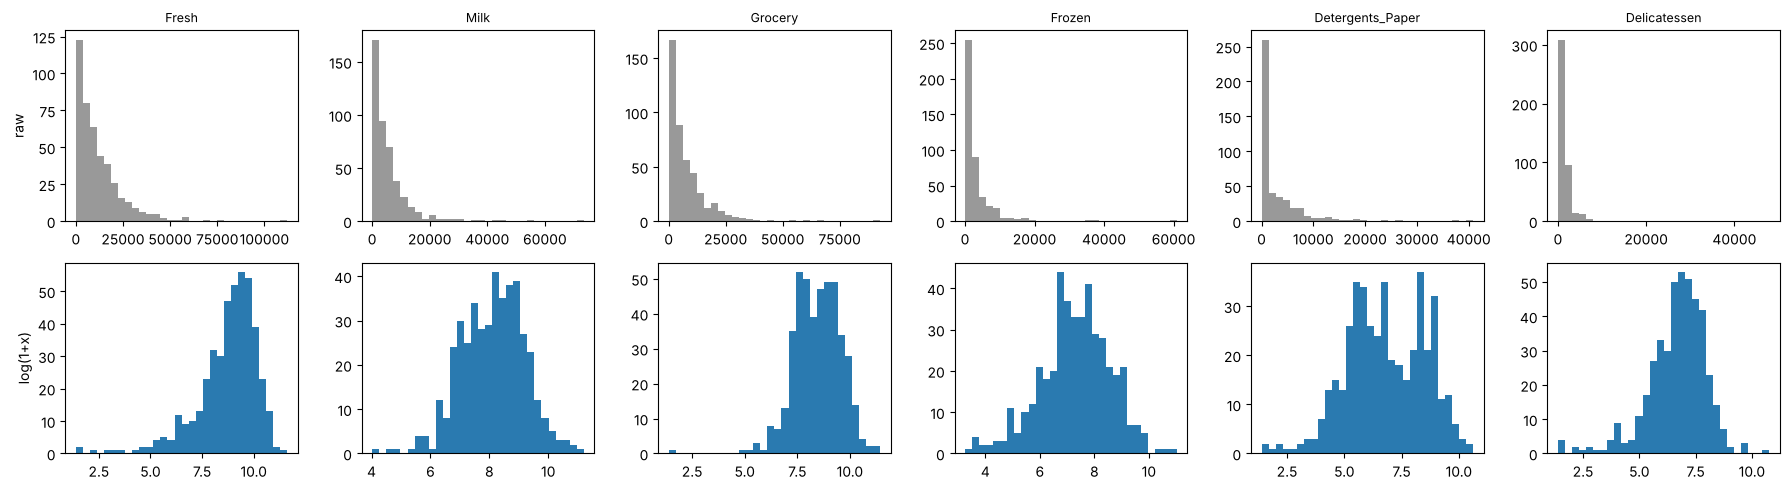

log skew: {'Fresh': -1.58, 'Milk': -0.22, 'Grocery': -0.67, 'Frozen': -0.35, 'Detergents_Paper': -0.24, 'Delicatessen': -1.09}
rows with |z|>3  raw: 26  log: 18


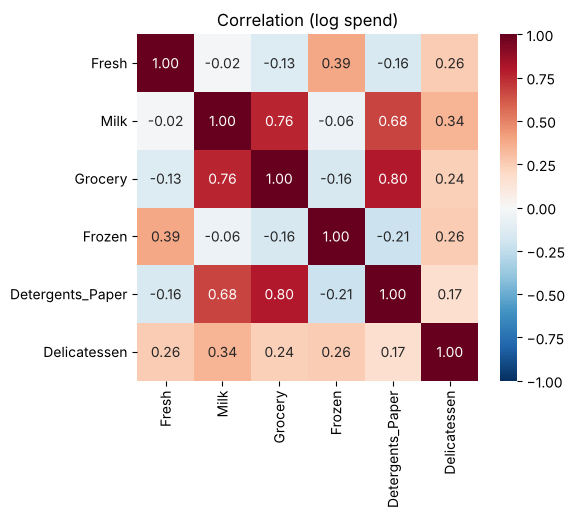

                  Channel  Region
Channel              1.00    0.06
Region               0.06    1.00
Fresh               -0.17    0.06
Milk                 0.46    0.03
Grocery              0.61    0.01
Frozen              -0.20   -0.02
Detergents_Paper     0.64   -0.00
Delicatessen         0.06    0.05


In [2]:
print(df[sp].skew().round(2))
print(df.Channel.value_counts(normalize=True).round(2).to_dict(), df.Region.value_counts(normalize=True).round(2).to_dict())
X=df[sp].astype(float); L=np.log1p(X)
fig,ax=plt.subplots(2,6,figsize=(18,5))
for i,c in enumerate(sp):
    ax[0,i].hist(X[c],bins=30,color='#999');ax[0,i].set_title(c,fontsize=9)
    ax[1,i].hist(L[c],bins=30,color='#2a7ab0')
ax[0,0].set_ylabel('raw');ax[1,0].set_ylabel('log(1+x)');plt.tight_layout();plt.show()
print('log skew:',L.skew().round(2).to_dict())
z=(X-X.mean())/X.std(); zl=(L-L.mean())/L.std()
print('rows with |z|>3  raw:',(z.abs()>3).any(axis=1).sum(),' log:',(zl.abs()>3).any(axis=1).sum())
plt.figure(figsize=(5.5,4.5));sns.heatmap(L.corr(),annot=True,fmt='.2f',cmap='RdBu_r',vmin=-1,vmax=1);plt.title('Correlation (log spend)');plt.show()
print(df[['Channel','Region']+sp].corr().round(2)[['Channel','Region']])
Xs=StandardScaler().fit_transform(L)

**Justification:** Channel/Region are nominal, so they are excluded from distance calculations and used only for validation. Spend is heavily right-skewed, so log(1+x) is applied; then z-scoring puts all categories on one scale. Outliers are kept (large customers matter commercially; log limits their leverage; DBSCAN flags them).

### Cluster tendency (Hopkins statistic; 0.5 = random, near 1 = clusterable)

In [3]:
def hopkins(A,seed=0,m=None):
    rng=np.random.default_rng(seed); n=len(A); m=m or int(.1*n)
    nn=NearestNeighbors(n_neighbors=2).fit(A)
    idx=rng.choice(n,m,replace=False)
    w=nn.kneighbors(A[idx],2)[0][:,1]
    U=rng.uniform(A.min(0),A.max(0),(m,A.shape[1]))
    u=nn.kneighbors(U,1)[0][:,0]
    return u.sum()/(u.sum()+w.sum())
Xr=StandardScaler().fit_transform(X)
print('log+standardised:',np.mean([hopkins(Xs,s) for s in range(50)]).round(3))
print('raw standardised (outlier-inflated):',np.mean([hopkins(Xr,s) for s in range(50)]).round(3))
print('uniform random:',np.mean([hopkins(np.random.default_rng(1).uniform(size=(440,6)),s) for s in range(50)]).round(3))

log+standardised: 0.798
raw standardised (outlier-inflated): 0.937


uniform random: 0.5


## 2. Comparing clustering methods

,k,inertia,silhouette,DB,CH,ARI_vs_Channel
0,2,1844.064,0.290,1.352,189.050,0.514
1,3,1553.340,0.259,1.344,152.855,0.346
2,4,1386.863,0.188,1.541,131.320,0.280
3,5,1266.149,0.192,1.484,118.000,0.212
4,6,1174.717,0.193,1.420,108.270,0.200
5,7,1086.109,0.198,1.385,103.249,0.201
6,8,1022.890,0.196,1.365,97.565,0.194


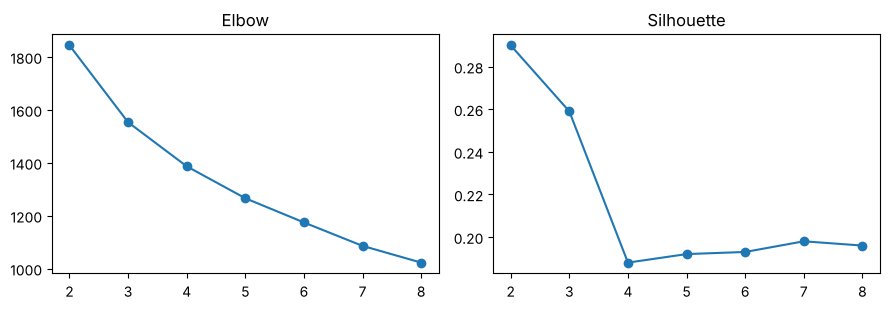

Bootstrap stability (mean ARI): {2: np.float64(0.91), 3: np.float64(0.79), 4: np.float64(0.66), 5: np.float64(0.58)}


In [4]:
ch=df.Channel.values; rows=[]
for k in range(2,9):
    km=KMeans(k,n_init=20,random_state=0).fit(Xs)
    rows.append((k,km.inertia_,silhouette_score(Xs,km.labels_),davies_bouldin_score(Xs,km.labels_),calinski_harabasz_score(Xs,km.labels_),adjusted_rand_score(ch,km.labels_)))
kdf=pd.DataFrame(rows,columns=['k','inertia','silhouette','DB','CH','ARI_vs_Channel']).round(3); display(kdf)
fig,ax=plt.subplots(1,2,figsize=(9,3.2));ax[0].plot(kdf.k,kdf.inertia,'o-');ax[0].set_title('Elbow');ax[1].plot(kdf.k,kdf.silhouette,'o-');ax[1].set_title('Silhouette');plt.tight_layout();plt.show()
def stab(k):
    base=KMeans(k,n_init=20,random_state=0).fit(Xs).labels_; r=[]
    for s in range(30):
        i=resample(np.arange(440),random_state=s); l=KMeans(k,n_init=10,random_state=s).fit(Xs[i]).predict(Xs); r.append(adjusted_rand_score(base,l))
    return round(np.mean(r),2)
print('Bootstrap stability (mean ARI):',{k:stab(k) for k in [2,3,4,5]})

,linkage,k,cophenetic,silhouette,DB,sizes
0,ward,2,0.484,0.258,1.600,"[178, 262]"
1,ward,3,0.484,0.255,1.539,"[262, 53, 125]"
2,ward,4,0.484,0.202,1.521,"[53, 208, 125, 54]"
3,ward,5,0.484,0.203,1.386,"[208, 18, 125, 54, 35]"
4,complete,2,0.654,0.322,1.554,"[38, 402]"
5,complete,3,0.654,0.298,1.402,"[402, 33, 5]"
6,complete,4,0.654,0.260,1.292,"[33, 391, 5, 11]"
7,complete,5,0.654,0.228,1.197,"[391, 24, 5, 11, 9]"
8,average,2,0.745,0.569,0.883,"[2, 438]"
9,average,3,0.745,0.542,0.307,"[438, 1, 1]"


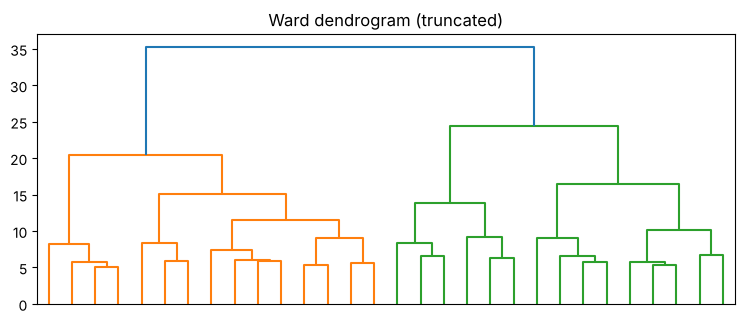

In [5]:
rows=[]
for link in ['ward','complete','average','single']:
    c=cophenet(linkage(Xs,link),pdist(Xs))[0]
    for k in [2,3,4,5]:
        lab=AgglomerativeClustering(k,linkage=link).fit_predict(Xs)
        rows.append((link,k,round(c,3),round(silhouette_score(Xs,lab),3),round(davies_bouldin_score(Xs,lab),3),np.bincount(lab).tolist()))
display(pd.DataFrame(rows,columns=['linkage','k','cophenetic','silhouette','DB','sizes']))
plt.figure(figsize=(9,3.5));dendrogram(linkage(Xs,'ward'),truncate_mode='lastp',p=30,no_labels=True);plt.title('Ward dendrogram (truncated)');plt.show()

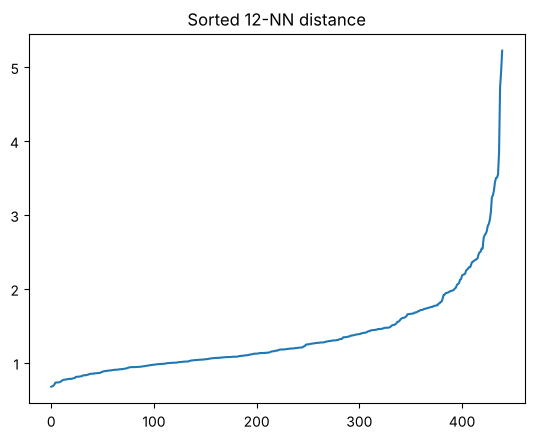

,eps,minPts,clusters,noise,silhouette_nonnoise,sizes
0,0.6,6,3,408,0.599,"[18, 7, 7]"
1,0.6,12,0,440,NaN,[]
2,0.8,6,3,262,0.324,"[83, 88, 7]"
3,0.8,12,2,346,0.552,"[44, 50]"
4,1.0,6,2,129,0.254,"[300, 11]"
5,1.0,12,1,183,NaN,[257]
6,1.2,6,1,80,NaN,[360]
7,1.2,12,1,105,NaN,[335]
8,1.4,6,1,56,NaN,[384]
9,1.4,12,1,67,NaN,[373]


In [6]:
kd=np.sort(NearestNeighbors(n_neighbors=12).fit(Xs).kneighbors(Xs)[0][:,-1]); plt.plot(kd);plt.title('Sorted 12-NN distance');plt.show()
rows=[]
for e in [0.6,0.8,1.0,1.2,1.4,1.6]:
  for ms in [6,12]:
    lab=DBSCAN(eps=e,min_samples=ms).fit_predict(Xs); m=lab!=-1; nc=len(set(lab))-(1 if -1 in lab else 0)
    s=silhouette_score(Xs[m],lab[m]) if nc>1 else np.nan
    rows.append((e,ms,nc,(~m).sum(),round(s,3),np.bincount(lab[m]).tolist() if m.any() else []))
display(pd.DataFrame(rows,columns=['eps','minPts','clusters','noise','silhouette_nonnoise','sizes']))

## 3. Final segments (K-means, k = 4) and comparison plots

ARI kmeans4 vs ward4: 0.39
PCA variance: [0.44 0.27]


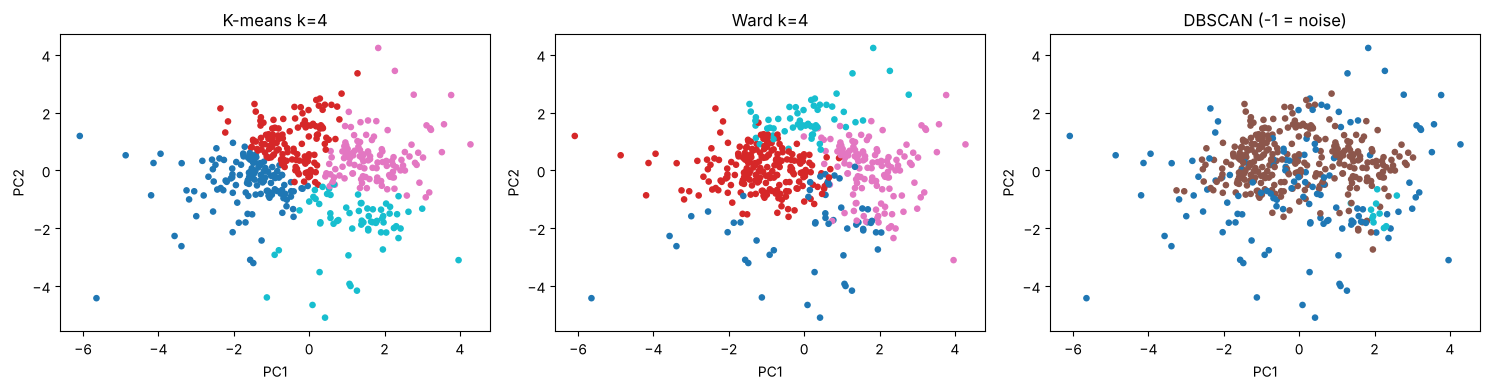

In [7]:
km4=KMeans(4,n_init=50,random_state=0).fit(Xs).labels_
w4=AgglomerativeClustering(4,linkage='ward').fit_predict(Xs)
db=DBSCAN(eps=1.0,min_samples=6).fit_predict(Xs)
print('ARI kmeans4 vs ward4:',round(adjusted_rand_score(km4,w4),2))
P=PCA(2).fit_transform(Xs); print('PCA variance:',PCA(2).fit(Xs).explained_variance_ratio_.round(2))
fig,ax=plt.subplots(1,3,figsize=(15,4))
for a,l,t in zip(ax,[km4,w4,db],['K-means k=4','Ward k=4','DBSCAN (-1 = noise)']):
    a.scatter(P[:,0],P[:,1],c=l,cmap='tab10',s=14);a.set_title(t);a.set_xlabel('PC1');a.set_ylabel('PC2')
plt.tight_layout();plt.show()

In [8]:
# Label numbers can differ by sklearn version, so name segments from their profile instead of fixed ids.
d=df.copy(); d['cluster']=km4
prof=d.groupby('cluster')[sp].median().round(0); prof['n']=d.groupby('cluster').size()
prof['avg_total']=d.groupby('cluster')[sp].sum().sum(1).div(prof.n).round(0)
retail=d.groupby('cluster').Channel.apply(lambda s:(s==2).mean())
big=prof[prof.Fresh==prof.Fresh.max()].index[0]      # highest median Fresh -> large food-service
nofresh=prof.Fresh.idxmin()                          # lowest Fresh -> dry goods & cleaning
rest=[c for c in prof.index if c not in (big,nofresh)]
retailc=max(rest,key=lambda c:retail[c]); small=[c for c in rest if c!=retailc][0]
names={small:'Small fresh-food outlets',big:'Large fresh & frozen food-service',retailc:'Big-basket grocery & dairy retailers',nofresh:'Dry-goods & cleaning-focused buyers'}
prof['segment']=prof.index.map(names); display(prof)
sh=d.groupby('cluster')[sp].sum(); display((sh.div(sh.sum(1),axis=0)*100).round(0))
display((pd.crosstab(d.cluster,d.Channel,normalize='index')*100).round(0))
display((pd.crosstab(d.cluster,d.Region,normalize='index')*100).round(0))
d['segment']=d.cluster.map(names); d.to_csv('wholesale-customers-segmented.csv',index=False)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,n,avg_total,segment
cluster,,,,,,,,,
0,7814.0,1112.0,1820.0,1386.0,224.0,432.0,130,16324.0,Small fresh-food outlets
1,16933.0,3090.0,3417.0,4324.0,523.0,1365.0,129,35487.0,Large fresh & frozen food-service
2,8190.0,8579.0,12477.0,1455.0,4666.0,1776.0,115,52525.0,Big-basket grocery & dairy retailers
3,1190.0,6672.0,10479.0,356.0,4218.0,303.0,66,28472.0,Dry-goods & cleaning-focused buyers


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
cluster,,,,,,
0,59.0,9.0,13.0,13.0,2.0,4.0
1,54.0,11.0,12.0,17.0,2.0,5.0
2,23.0,23.0,31.0,4.0,13.0,5.0
3,10.0,25.0,43.0,2.0,18.0,2.0


Channel,1,2
cluster,,
0,99.0,1.0
1,95.0,5.0
2,19.0,81.0
3,38.0,62.0


Region,1,2,3
cluster,,,
0,20.0,8.0,72.0
1,17.0,13.0,70.0
2,17.0,10.0,73.0
3,15.0,11.0,74.0
